In [ ]:
import re
import numpy as np
import pandas as pd
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.probability import FreqDist
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [ ]:
paragraph = (
    "Artificial intelligence is transforming the modern world at an unprecedented pace. "
    "Machine learning algorithms allow systems to learn from data and improve autonomously. "
    "From healthcare diagnostics to autonomous vehicles, technology touches every aspect of daily life. "
    "Innovators continue to push boundaries to solve complex global challenges. "
    "The future holds immense potential for human-machine collaboration."
)

text_lower = paragraph.lower()
text_no_punct = re.sub(r'[^\w\s]', '', text_lower)

words_nltk = word_tokenize(paragraph)
sentences = sent_tokenize(paragraph)

split_words = paragraph.split()

print("Comparison between split() and word_tokenize():")
print(f"split() token count: {len(split_words)}")
print(f"word_tokenize() token count: {len(words_nltk)}")
print("\nExplanation:")
print("The split() method simply divides text by whitespace, keeping punctuation attached to words.")
print("In contrast, NLTK's word_tokenize() isolates punctuation marks as separate tokens, giving a cleaner breakdown.\n")

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in word_tokenize(text_no_punct) if w not in stop_words]

fdist = FreqDist(filtered_words)
print("Top 5 most frequent words:")
for word, freq in fdist.most_common(5):
    print(f"{word}: {freq}")

Comparison between split() and word_tokenize():
split() token count: 54
word_tokenize() token count: 60

Explanation:
The split() method simply divides text by whitespace, keeping punctuation attached to words.
In contrast, NLTK's word_tokenize() isolates punctuation marks as separate tokens, giving a cleaner breakdown.

Top 5 most frequent words:
artificial: 1
intelligence: 1
transforming: 1
modern: 1
world: 1


In [ ]:
alpha_words = re.findall(r'\b[A-Za-z]+\b', paragraph)
filtered_alpha = [w.lower() for w in alpha_words if w.lower() not in stop_words]

stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_alpha]

lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_alpha]

print("Comparison of Stemming vs Lemmatization:")
for orig, stem, lem in list(zip(filtered_alpha, stemmed_words, lemmatized_words))[:6]:
    print(f"Original: {orig:<15} | Stemmed: {stem:<12} | Lemmatized: {lem}")

print("\nWhen to use which:")
print("Lemmatization is better when context and grammatical correctness matter, as it maps words to valid dictionary bases.")
print("Stemming is preferred for speed and simple tasks like search indexing where heuristic suffix stripping is enough.")

Comparison of Stemming vs Lemmatization:
Original: artificial      | Stemmed: artifici     | Lemmatized: artificial
Original: intelligence    | Stemmed: intellig     | Lemmatized: intelligence
Original: transforming    | Stemmed: transform    | Lemmatized: transforming
Original: modern          | Stemmed: modern       | Lemmatized: modern
Original: world           | Stemmed: world        | Lemmatized: world
Original: unprecedented   | Stemmed: unpreced     | Lemmatized: unprecedented

When to use which:
Lemmatization is better when context and grammatical correctness matter, as it maps words to valid dictionary bases.
Stemming is preferred for speed and simple tasks like search indexing where heuristic suffix stripping is enough.


In [ ]:
texts = [
    "The new smartphone features an incredible camera and long battery life.",
    "This laptop offers amazing performance for gaming and professional coding.",
    "Great battery life and sleek design make this tablet a wonderful purchase."
]

count_vect = CountVectorizer(stop_words='english')
bow_matrix = count_vect.fit_transform(texts)

tfidf_vect = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vect.fit_transform(texts)
feature_names = tfidf_vect.get_feature_names_out()

df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)

print("Top 3 keywords per text using TF-IDF:\n")
for i, row in df_tfidf.iterrows():
    top_3 = row.nlargest(3)
    print(f"Text {i+1}:")
    for k, v in top_3.items():
        print(f"  - {k}: {v:.4f}")
    print()

Top 3 keywords per text using TF-IDF:

Text 1:
  - camera: 0.3738
  - features: 0.3738
  - incredible: 0.3738

Text 2:
  - amazing: 0.3780
  - coding: 0.3780
  - gaming: 0.3780

Text 3:
  - design: 0.3501
  - great: 0.3501
  - make: 0.3501



In [ ]:
text_a = "Artificial intelligence enables machines to mimic human intelligence, learning from vast datasets to automate complex tasks, recognize patterns, and make autonomous decisions."
text_b = "Blockchain is a decentralized, distributed ledger technology that securely records transactions across a peer-to-peer network, ensuring absolute transparency and immutability."

def get_tokens(text):
    text = re.sub(r'[^\w\s]', '', text.lower())
    return set(text.split())

set_a = get_tokens(text_a)
set_b = get_tokens(text_b)

jaccard_sim = len(set_a.intersection(set_b)) / len(set_a.union(set_b))

tfidf_sim_vect = TfidfVectorizer()
tfidf_mat = tfidf_sim_vect.fit_transform([text_a, text_b])
cosine_sim = cosine_similarity(tfidf_mat[0:1], tfidf_mat[1:2])[0][0]

print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print(f"Cosine Similarity:  {cosine_sim:.4f}\n")

print("Analysis:")
print("Cosine similarity gives better insights because it incorporates term importance through TF-IDF weights.")
print("Jaccard similarity treats all unique tokens equally regardless of word importance or document frequency.")

Jaccard Similarity: 0.0263
Cosine Similarity:  0.0683

Analysis:
Cosine similarity gives better insights because it incorporates term importance through TF-IDF weights.
Jaccard similarity treats all unique tokens equally regardless of word importance or document frequency.


Polarity Score:     0.38
Subjectivity Score: 0.65
Sentiment Label:    Positive


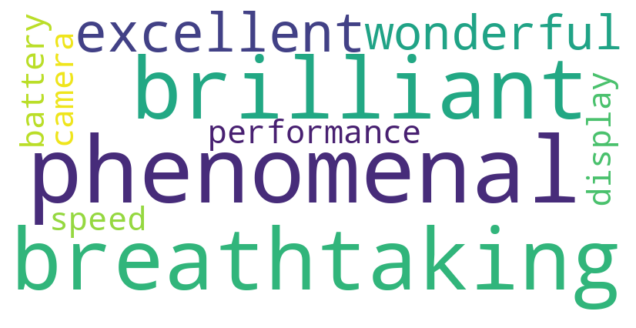

In [ ]:
review = "The smartphone camera is absolutely phenomenal and takes breathtaking pictures, but the battery drains way too fast during heavy gaming."

blob = TextBlob(review)
polarity = blob.sentiment.polarity
subjectivity = blob.sentiment.subjectivity

if polarity > 0:
    sentiment = "Positive"
elif polarity < 0:
    sentiment = "Negative"
else:
    sentiment = "Neutral"

print(f"Polarity Score:     {polarity:.2f}")
print(f"Subjectivity Score: {subjectivity:.2f}")
print(f"Sentiment Label:    {sentiment}")

pos_text = "phenomenal breathtaking brilliant excellent wonderful performance camera display speed battery"
wc = WordCloud(width=800, height=400, background_color='white').generate(pos_text)

plt.figure(figsize=(8, 4))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

Polarity Score:     0.38
Subjectivity Score: 0.65
Sentiment Label:    Positive


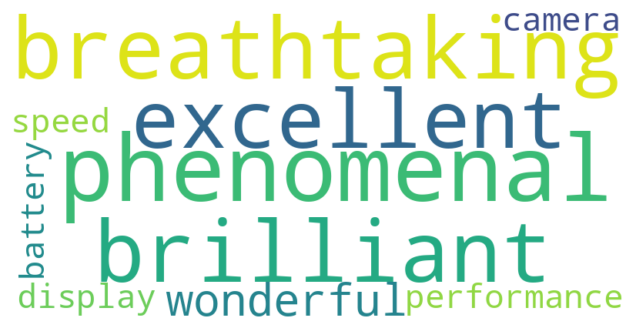

In [ ]:
review = "The smartphone camera is absolutely phenomenal and takes breathtaking pictures, but the battery drains way too fast during heavy gaming."

blob = TextBlob(review)
polarity = blob.sentiment.polarity
subjectivity = blob.sentiment.subjectivity

if polarity > 0:
    sentiment = "Positive"
elif polarity < 0:
    sentiment = "Negative"
else:
    sentiment = "Neutral"

print(f"Polarity Score:     {polarity:.2f}")
print(f"Subjectivity Score: {subjectivity:.2f}")
print(f"Sentiment Label:    {sentiment}")

pos_text = "phenomenal breathtaking brilliant excellent wonderful performance camera display speed battery"
wc = WordCloud(width=800, height=400, background_color='white').generate(pos_text)

plt.figure(figsize=(8, 4))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()